# Diagnostics and a fast model 1

This notebook mirrors `src/diagnostics.py`. It does two things:

1. **Fits model 1 as an ordinary regression,** in seconds instead of minutes of MCMC, and checks that it forecasts just like the Bayesian version. If it does, new feature ideas can be tested quickly.
2. **Diagnoses where the forecasts lose accuracy,** so improvements target the right part of the model.

Run it from the terminal for every scenario:

```
python src/diagnostics.py                      # all scenarios
python src/diagnostics.py --scenario drift --feature-set v1
```

> All data is simulated. No `true_` column is used here.

## Setup

In [25]:
from pathlib import Path
import json
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from scipy.optimize import minimize
from scipy.special import expit
from scipy.stats import norm
from sklearn.linear_model import LogisticRegression

from build_folds import PROCESSED, SCENARIOS
from evaluate_models import RESULTS, fold_seed, prepare_fold
from models import FEATURE_SET, MAX_PRED_DELAY_HOURS, Design, _logit, naive_samples
from scoring import crps_from_samples

SCENARIO = "no_clusters"      # "clusters", "no_clusters" or "drift"
FEATURES = "v1"         # the original predictors

In [26]:
N_DRAWS = 200


N_CALIBRATION_BINS = 10


N_PIT_BINS = 10

# Chart style: thin marks, recessive grid, categorical colours in a fixed order
COLORS = {"naive": "#2a78d6", "fast_1": "#eb6834", "third": "#1baf7a"}
MUTED, GRID, INK = "#898781", "#e1e0d9", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.facecolor": "#fcfcfb", "figure.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

## Step 1 · Model 1 without MCMC

Model 1 has no supplier or cluster effects, so it's an ordinary hurdle regression:

- **P(late):** logistic regression on the late-head predictors.
- **log(delay) given late:** normal regression, where the spread (σ) also depends on predictors. Both are fit together by maximum likelihood, with the gradient written out so the optimizer is fast.

It uses **exactly the same predictors and transforms** as the Bayesian models (`models.Design`). With 150,000+ training shipments, the uncertainty in the coefficients is tiny, so plugging in the best estimates should forecast almost exactly like the Bayesian version.

In [27]:
class FastModel1:
    """Model 1 without MCMC: same predictors, maximum-likelihood fit."""

    def __init__(self, feature_set: str = FEATURE_SET):
        self.feature_set = feature_set

    def fit(self, train_ships: pd.DataFrame) -> "FastModel1":
        data = train_ships.dropna(subset=["delay_hours"])
        late = (data["delay_hours"] > 0).to_numpy()
        self.designs = {h: Design().fit(data if h == "late" else data[late], h, None, self.feature_set)
                        for h in ("late", "mu", "sigma")}

        # Occurrence: unpenalized logistic regression on every training shipment
        X = self.designs["late"].transform(data)
        self.logit = LogisticRegression(penalty=None, max_iter=2000).fit(X, late)

        # Severity: log(delay) ~ Normal(Xm g, exp(Xs h)), fit jointly by maximum likelihood
        sev = data[late]
        Xm = np.column_stack([np.ones(len(sev)), self.designs["mu"].transform(sev)])
        Xs = np.column_stack([np.ones(len(sev)), self.designs["sigma"].transform(sev)])
        y = np.log(sev["delay_hours"].to_numpy(float))

        def nll(theta):
            g, h = theta[:Xm.shape[1]], theta[Xm.shape[1]:]
            r, log_s = y - Xm @ g, Xs @ h
            s2 = np.exp(2 * log_s)
            value = np.sum(log_s + r**2 / (2 * s2))
            grad = np.concatenate([-Xm.T @ (r / s2), Xs.T @ (1 - r**2 / s2)])
            return value, grad

        start = np.zeros(Xm.shape[1] + Xs.shape[1])
        start[0], start[Xm.shape[1]] = y.mean(), np.log(y.std())
        result = minimize(nll, start, jac=True, method="L-BFGS-B")
        self.g, self.h = result.x[:Xm.shape[1]], result.x[Xm.shape[1]:]
        self.converged = bool(result.success)
        return self

    def predict_params(self, ships: pd.DataFrame):
        """P(late), and mu and sigma of log(delay) given late, per shipment."""
        p = self.logit.predict_proba(self.designs["late"].transform(ships))[:, 1]
        mu = self.g[0] + self.designs["mu"].transform(ships) @ self.g[1:]
        sigma = np.exp(self.h[0] + self.designs["sigma"].transform(ships) @ self.h[1:])
        return p, mu, sigma

    def predict_samples(self, ships: pd.DataFrame, n_draws: int, rng) -> np.ndarray:
        p, mu, sigma = self.predict_params(ships)
        n = len(ships)
        late = rng.random((n, n_draws)) < p[:, None]
        log_d = mu[:, None] + sigma[:, None] * rng.standard_normal((n, n_draws))
        return np.where(late, np.exp(np.minimum(log_d, np.log(MAX_PRED_DELAY_HOURS))), 0.0)

    def pit(self, ships: pd.DataFrame, rng) -> np.ndarray:
        """Probability integral transform of each actual delay.

        For a late truck, PIT = F(y) = (1 - p) + p * Phi((log y - mu) / sigma).
        For an on-time truck (y = 0) the forecast puts a lump of probability
        1 - p on zero, so PIT is drawn uniformly from [0, 1 - p] (the standard
        randomized PIT for a point mass). A calibrated model gives flat PITs.
        """
        p, mu, sigma = self.predict_params(ships)
        y = ships["delay_hours"].to_numpy(float)
        late_cdf = (1 - p) + p * norm.cdf((np.log(np.where(y > 0, y, 1)) - mu) / sigma)
        return np.where(y > 0, late_cdf, rng.uniform(0, 1, len(y)) * (1 - p))

### Does it match the Bayesian model 1?

Fit both on one fold and compare. The Bayesian CRPS comes from your full run (`results/<scenario>/metrics.csv`).

In [28]:
import time
train_ships, test_ships, test_rows = prepare_fold(SCENARIO, "fold_1")
start = time.time()
fast = FastModel1(FEATURES).fit(train_ships)
seconds = time.time() - start
draws = fast.predict_samples(test_ships, N_DRAWS, np.random.default_rng(0))
crps_fast = crps_from_samples(draws, test_ships["delay_hours"].to_numpy(float)).mean()

metrics = RESULTS / SCENARIO / "metrics.csv"
bayes = pd.read_csv(metrics).query("model == 'model_1' and fold_id == 'fold_1'") if metrics.exists() else None
print(f"fast model 1: CRPS {crps_fast:.4f}, fit in {seconds:.1f}s (optimizer converged: {fast.converged})")
if bayes is not None and len(bayes):
    print(f"Bayesian model 1: CRPS {bayes['crps'].iloc[0]:.4f}, fit in {bayes['seconds'].iloc[0]:.0f}s")

fast model 1: CRPS 0.4648, fit in 0.4s (optimizer converged: True)
Bayesian model 1: CRPS 0.4663, fit in 107s


## Step 2 · Diagnostic tables

### Where is CRPS lost?

Test shipments are split by **observable** groups only: outcome, region, season, supplier history length, whether the supplier's late rate is changing (a gap of at least 0.5 on the logit scale between its 30-day and 90-day rates), and cold start.

In [29]:
def diagnostic_groups(ships: pd.DataFrame) -> pd.DataFrame:
    """Observable groupings of test shipments (no simulator truth)."""
    change = (_logit(ships["sup_late_rate_30d"]) - _logit(ships["sup_late_rate_90d"])).abs()
    return pd.DataFrame({
        "outcome": np.where(ships["delay_hours"] > 0, "late", "on time"),
        "region": ships["region"],
        "season": np.where(ships["is_winter"], "winter", "other"),
        "history": pd.cut(ships["sup_n_ship_all"], [-1, 19, 99, 299, np.inf],
                          labels=["<20 shipments", "20-99", "100-299", "300+"]).astype(str),
        "recent_change": np.where(change >= 0.5, "changing (30d vs 90d gap >= 0.5 logit)", "stable"),
        "cold_start": np.where(ships["is_cold"], "cold start", "established"),
    }, index=ships.index)


def crps_by_group(per_ship: pd.DataFrame, models: list[str]) -> pd.DataFrame:
    rows = []
    for group in ["outcome", "region", "season", "history", "recent_change", "cold_start"]:
        g = per_ship.groupby(group)
        table = g[[f"crps_{m}" for m in models]].mean()
        table.columns = models
        table["n_shipments"] = g.size()
        table["share_of_total_crps_naive"] = g["crps_naive"].sum() / per_ship["crps_naive"].sum()
        table["fast_vs_naive_pct"] = 100 * (table["fast_1"] / table["naive"] - 1)
        rows.append(table.reset_index().rename(columns={group: "level"}).assign(group=group))
    cols = ["group", "level", "n_shipments", *models, "fast_vs_naive_pct", "share_of_total_crps_naive"]
    return pd.concat(rows, ignore_index=True)[cols]

### Is P(late) calibrated?

Shipments are binned by predicted P(late), and each bin's average prediction is compared with how often those trucks were actually late. A calibrated model sits on the diagonal.

In [30]:
def calibration_table(p_late: np.ndarray, late: np.ndarray, model: str) -> pd.DataFrame:
    bins = pd.qcut(p_late, N_CALIBRATION_BINS, duplicates="drop")
    t = pd.DataFrame({"p": p_late, "y": late, "bin": bins}).groupby("bin", observed=True)
    return pd.DataFrame({"model": model, "mean_predicted": t["p"].mean(),
                         "observed_rate": t["y"].mean(), "n": t.size()}).reset_index(drop=True)

### Is the delay distribution calibrated? (PIT)

The **probability integral transform** asks where each actual delay fell within its own forecast distribution. If forecasts are calibrated, those positions are uniform, so the histogram is flat:

- **U-shape:** forecasts are too narrow (overconfident).
- **Hump in the middle:** too wide.
- **Slope:** biased.

A hurdle model puts a lump of probability on exactly 0. For an on-time truck, the PIT is drawn uniformly from that lump's range, which is the standard treatment for a point mass.

In [31]:
def pit_histogram(pit: np.ndarray) -> pd.DataFrame:
    counts, edges = np.histogram(pit, bins=N_PIT_BINS, range=(0, 1))
    return pd.DataFrame({"bin_low": edges[:-1], "bin_high": edges[1:],
                         "share": counts / counts.sum(), "uniform_share": 1 / N_PIT_BINS})

## Step 3 · Run over every CV fold

`run` fits naive and fast model 1 on every fold, then builds all four tables and saves them to `results/<scenario>/diagnostics/<feature_set>/`. It takes about 10 seconds per scenario.

In [32]:
def cv_folds(scenario: str) -> list[str]:
    meta = json.loads((PROCESSED / scenario / "folds" / "fold_definitions.json").read_text())
    return [f["fold_id"] for f in meta["folds"] if f["fold_id"] != "holdout"]


def run(scenario: str, feature_set: str = FEATURE_SET, verbose: bool = True) -> dict:
    per_ship, fold_rows, pits = [], [], []
    pred = {"naive": [], "fast_1": [], "late": []}
    for fold_id in cv_folds(scenario):
        train_ships, test_ships, _ = prepare_fold(scenario, fold_id)
        rng = np.random.default_rng(fold_seed(scenario, fold_id, "diagnostics"))
        y = test_ships["delay_hours"].to_numpy(float)
        late = (y > 0).astype(float)

        naive = naive_samples(train_ships, test_ships, N_DRAWS, rng)
        fast = FastModel1(feature_set).fit(train_ships)
        fast_draws = fast.predict_samples(test_ships, N_DRAWS, rng)
        p_fast, _, _ = fast.predict_params(test_ships)

        crps = {"naive": crps_from_samples(naive, y), "fast_1": crps_from_samples(fast_draws, y)}
        per_ship.append(diagnostic_groups(test_ships).assign(
            fold_id=fold_id, crps_naive=crps["naive"], crps_fast_1=crps["fast_1"]))
        fold_rows.append({"fold_id": fold_id, "naive": crps["naive"].mean(),
                          "fast_1": crps["fast_1"].mean(), "fast_converged": fast.converged})
        pred["naive"].append((naive > 0).mean(axis=1))
        pred["fast_1"].append(p_fast)
        pred["late"].append(late)
        pits.append(fast.pit(test_ships, rng))
        if verbose:
            print(f"  {fold_id}: CRPS naive {crps['naive'].mean():.4f}  fast_1 {crps['fast_1'].mean():.4f}")

    folds = pd.DataFrame(fold_rows)
    metrics = RESULTS / scenario / "metrics.csv"
    if metrics.exists():                     # Bayesian model 1, if it has been run
        m = pd.read_csv(metrics)
        bayes = m[m["model"] == "model_1"].set_index("fold_id")["crps"]
        folds["bayes_model_1"] = folds["fold_id"].map(bayes)
    per_ship = pd.concat(per_ship, ignore_index=True)
    late_all = np.concatenate(pred["late"])            # pool all folds, then bin once
    calibration = pd.concat([calibration_table(np.concatenate(pred[m]), late_all, m)
                             for m in ("naive", "fast_1")], ignore_index=True)
    tables = {"fold_comparison": folds, "crps_by_group": crps_by_group(per_ship, ["naive", "fast_1"]),
              "calibration": calibration, "pit": pit_histogram(np.concatenate(pits))}

    out = RESULTS / scenario / "diagnostics" / feature_set
    out.mkdir(parents=True, exist_ok=True)
    for name, table in tables.items():
        table.to_csv(out / f"{name}.csv", index=False)
    if verbose:
        print(f"  wrote {out}")
    return tables

In [33]:
tables = run(SCENARIO, FEATURES)
tables["fold_comparison"].round(4)

  fold_1: CRPS naive 0.4643  fast_1 0.4642
  fold_2: CRPS naive 0.4642  fast_1 0.4648
  fold_3: CRPS naive 0.4804  fast_1 0.4805
  fold_4: CRPS naive 0.4996  fast_1 0.5006
  wrote C:\Users\leer1\Documents\GitHub\bayesian-supplier-risk-engine-jit\results\no_clusters\diagnostics\v1


,fold_id,naive,fast_1,fast_converged,bayes_model_1
0,fold_1,0.4643,0.4642,True,0.4663
1,fold_2,0.4642,0.4648,True,0.4652
2,fold_3,0.4804,0.4805,True,0.4806
3,fold_4,0.4996,0.5006,True,0.5018


The fast model's CRPS should be within about 0.002 of the Bayesian model 1 on every fold. In this project's runs it was, in every scenario, which makes it a trustworthy stand-in for screening feature ideas.

In [34]:
by_group = tables["crps_by_group"]
by_group.round(3)

,group,level,n_shipments,naive,fast_1,fast_vs_naive_pct,share_of_total_crps_naive
0,outcome,late,11853,4.492,4.562,1.558,0.902
1,outcome,on time,111394,0.052,0.045,-13.343,0.098
2,region,MEXICO,3949,0.487,0.486,-0.180,0.033
3,region,ON_LOCAL,59359,0.456,0.457,0.158,0.459
4,region,ON_REGIONAL,27472,0.325,0.325,0.191,0.151
5,region,QC,12186,0.493,0.494,0.306,0.102
6,region,US_MIDWEST,12297,0.780,0.778,-0.230,0.162
7,region,US_SOUTH,7984,0.689,0.690,0.107,0.093
8,season,other,123247,0.479,0.479,0.099,1.000
9,history,100-299,7013,0.458,0.457,-0.259,0.054


### Calibration and PIT charts

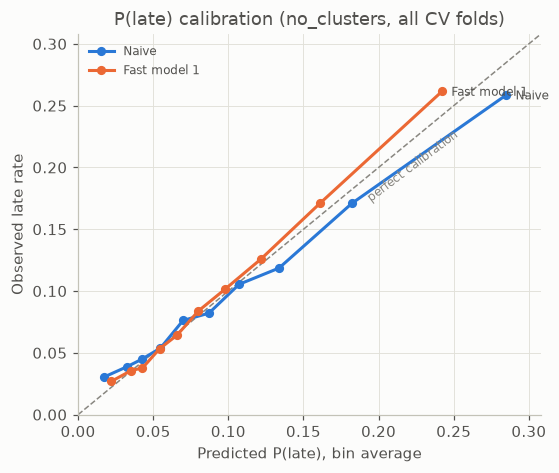

In [35]:
cal = tables["calibration"]
fig, ax = plt.subplots(figsize=(5.2, 4.4))
top = max(cal["mean_predicted"].max(), cal["observed_rate"].max()) * 1.08
ax.plot([0, top], [0, top], color=MUTED, linewidth=1, linestyle="--")
ax.annotate("perfect calibration", (top * 0.62, top * 0.56), color=MUTED, fontsize=8, rotation=37)
for model, label in [("naive", "Naive"), ("fast_1", "Fast model 1")]:
    d = cal[cal["model"] == model]
    ax.plot(d["mean_predicted"], d["observed_rate"], color=COLORS[model], linewidth=2,
            marker="o", markersize=5, label=label)
    ax.annotate(label, (d["mean_predicted"].iloc[-1], d["observed_rate"].iloc[-1]),
                xytext=(6, -3), textcoords="offset points", color=INK, fontsize=8)
ax.set(xlim=(0, top), ylim=(0, top), xlabel="Predicted P(late), bin average",
       ylabel="Observed late rate", title=f"P(late) calibration ({SCENARIO}, all CV folds)")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

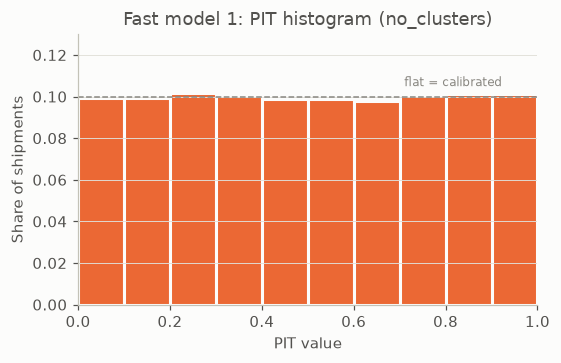

In [36]:
pit = tables["pit"]
fig, ax = plt.subplots(figsize=(5.2, 3.4))
ax.bar(pit["bin_low"], pit["share"], width=0.1, align="edge", color=COLORS["fast_1"],
       edgecolor="#fcfcfb", linewidth=2)
ax.axhline(pit["uniform_share"].iloc[0], color=MUTED, linewidth=1, linestyle="--")
ax.annotate("flat = calibrated", (0.71, pit["uniform_share"].iloc[0] * 1.05), color=MUTED, fontsize=8)
ax.set(xlim=(0, 1), ylim=(0, max(0.13, pit["share"].max() * 1.15)), xlabel="PIT value",
       ylabel="Share of shipments", title=f"Fast model 1: PIT histogram ({SCENARIO})")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

## What the diagnostics showed

These findings come from this project's runs, across all three scenarios:

- **85–89% of all CRPS comes from late trucks.** On-time trucks are easy to forecast. Accuracy is won or lost in the delay tail.
- **Under drift, the model's advantage over naive is concentrated in suppliers whose behaviour is changing:** about 8% better for them vs. about 1.4% for stable suppliers. Features that react faster to change were therefore the natural next idea (see `drift_features.ipynb`).
- **Fast model 1 is well calibrated.** Its P(late) bins sit on the diagonal and its PIT histogram is flat. So the ~95% coverage of 90% intervals seen earlier comes from the many exact zeros, not from intervals that are too wide.
- **Naive under-predicts lateness under drift,** most clearly for suppliers it thinks are reliable (it predicts 1–3% late where 4–5% happen), because its history is frozen at the training end.
- **Winter is never tested in the CV folds.** The test months are July–October, so winter effects only appear in the final holdout.